# Mini Project 1: Word Frequency in Tragedies

## Goal

Determine whether word-frequency patterns can distinguish authorship, and whether they stay consistent within a single author's body of work.

## Data Sources (Project Gutenberg)

- *Romeo and Juliet*: https://www.gutenberg.org/ebooks/1112.txt.utf-8
- *Macbeth*: https://www.gutenberg.org/ebooks/1533.txt.utf-8
- *The Duchess of Malfi*: https://www.gutenberg.org/ebooks/2232.txt.utf-8

## Comparisons

1. **Same author, different works:** *Romeo and Juliet* vs. *Macbeth* (both Shakespeare) — check whether Shakespeare's top word frequencies look similar across both plays.
2. **Different authors, similar genre/era:** *Macbeth* (Shakespeare) vs. *The Duchess of Malfi* (Webster) — both are Jacobean-era tragedies, so differences found are more likely attributable to authorial style than genre or period.
3. **Distinctive words:** identify words that appear in the top 15 of one play but not another, as candidate "signature" words tied to individual authorial style.

## Setup

Helper functions to fetch, clean, and count word frequencies

In [15]:
import requests, re, nltk
from bs4 import BeautifulSoup
from collections import Counter
import operator
import numpy as np
import pylab
import matplotlib.pyplot as plt

%matplotlib inline

nltk.download('stopwords')

# we may not care about the usage of stop words
stop_words = nltk.corpus.stopwords.words('english') + [
 'ut', '\'re','.', ',', '--', '\'s', '?', ')', '(', ':', '\'',
 '\"', '-', '}', '{', '&', '|', u'\u2014' ]

# We most likely would like to remove html markup
def cleanHtml(html):
    soup = BeautifulSoup(html, 'html.parser')
    return soup.get_text()

# We also want to remove special characters, quotes, etc. from each word
def cleanWord(w):
    wn = re.sub('[,\"\.\'&\|:@>*;/=]', "", w)
    # get rid of numbers
    return re.sub('^[0-9\.]*$', "", wn)

def stripGutenbergBoilerplate(text):
    start_match = re.search(r'\*\*\* START OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*', text, re.IGNORECASE)
    end_match = re.search(r'\*\*\* END OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*', text, re.IGNORECASE)
    start = start_match.end() if start_match else 0
    end = end_match.start() if end_match else len(text)
    return text[start:end]

# define a function to get text/clean/calculate frequency
def get_wf(URL):
    r = requests.get(URL)
    t = cleanHtml(r.text).lower()
    t = stripGutenbergBoilerplate(t)
    wds = re.split('\s+', t)
    for i in range(len(wds)):
        wds[i] = cleanWord(wds[i])
    wf = Counter(wds)
    for k in stop_words:
        wf.pop(k, None)
    tw = 0
    for w in wf:
        tw += wf[w]
    wfs = sorted(wf.items(), key=operator.itemgetter(1), reverse=True)
    ml = min(len(wfs), 15)
    # Reverse the list because barh plots items from the bottom
    return (wfs[0:ml][::-1], tw)

[nltk_data] Downloading package stopwords to /home/ncash3/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [16]:
def plotTwoLists(wf_ee, wf_bu, title):
    f = plt.figure(figsize=(10, 6))
    f.suptitle(title, fontsize=18)
    ax = f.add_subplot(111)
    ax.spines['top'].set_color('none')
    ax.spines['bottom'].set_color('none')
    ax.spines['left'].set_color('none')
    ax.spines['right'].set_color('none')
    ax.tick_params(labelcolor='w', top=False, bottom=False, left=False, right=False, labelsize=20)

    ax1 = f.add_subplot(121)
    plt.subplots_adjust(wspace=.6)

    pos = np.arange(len(wf_ee))
    ax1.tick_params(axis='both', which='major', labelsize=13)
    pylab.yticks(pos, [x[0] for x in wf_ee])
    ax1.barh(range(len(wf_ee)), [x[1] for x in wf_ee], align='center')
    ax1.yaxis.set_ticks_position('left')

    ax2 = f.add_subplot(122)
    ax2.tick_params(axis='both', which='major', labelsize=13)
    pos = np.arange(len(wf_bu))
    pylab.yticks(pos, [x[0] for x in wf_bu])
    ax2.barh(range(len(wf_bu)), [x[1] for x in wf_bu], align='center')
    ax2.yaxis.set_ticks_position('left')

## Get word frequencies for each play

In [17]:
# Same author comparison
(wf_rj, tw_rj) = get_wf('https://www.gutenberg.org/ebooks/1112.txt.utf-8')
(wf_mb, tw_mb) = get_wf('https://www.gutenberg.org/ebooks/1533.txt.utf-8')

# Different author comparison
(wf_dm, tw_dm) = get_wf('https://www.gutenberg.org/ebooks/2232.txt.utf-8')

## Comparison 1: Same Author — Romeo and Juliet vs. Macbeth (Shakespeare)

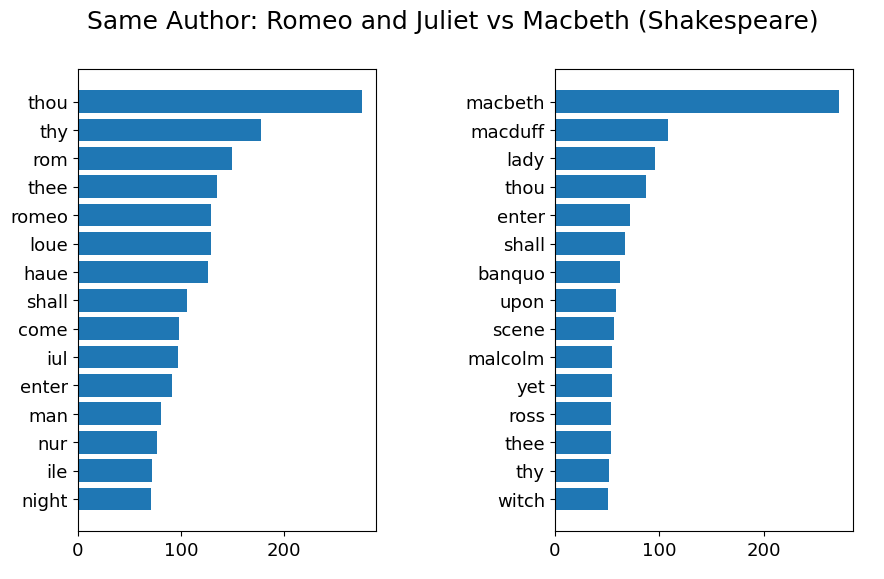

In [18]:
plotTwoLists(wf_rj, wf_mb, 'Same Author: Romeo and Juliet vs Macbeth (Shakespeare)')

## Comparison 2: Different Authors — Macbeth (Shakespeare) vs. The Duchess of Malfi (Webster)

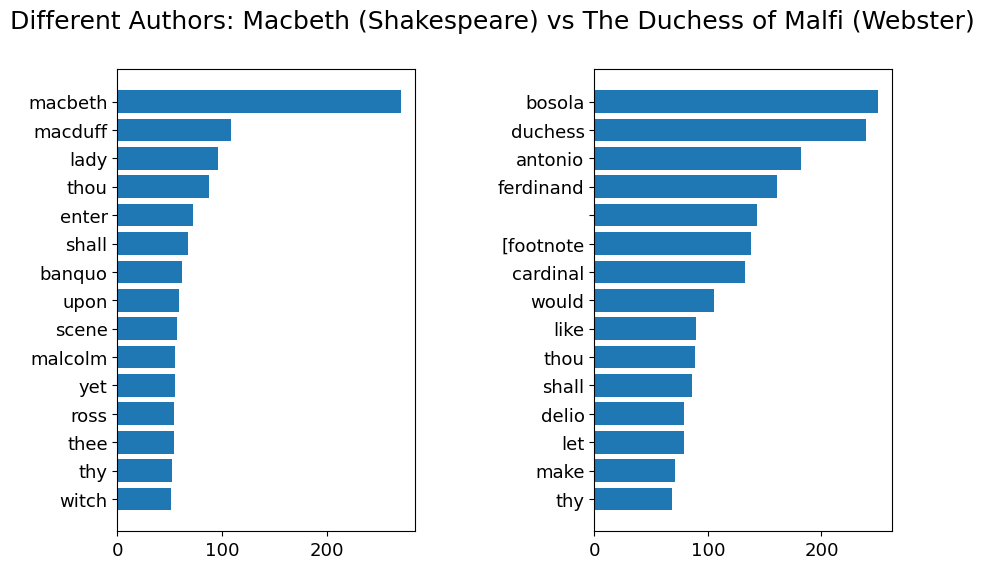

In [19]:
plotTwoLists(wf_mb, wf_dm, 'Different Authors: Macbeth (Shakespeare) vs The Duchess of Malfi (Webster)')

## Distinctive Words

Words that appear in one play's top 15 but not another's — candidate "signature" words tied to individual authorial style.

In [20]:
words_rj = set(w for w, c in wf_rj)
words_mb = set(w for w, c in wf_mb)
words_dm = set(w for w, c in wf_dm)

print("In Romeo & Juliet's top 15 but not Macbeth's:", words_rj - words_mb)
print("In Macbeth's top 15 but not Romeo & Juliet's:", words_mb - words_rj)
print()
print("In Macbeth's top 15 but not Duchess of Malfi's:", words_mb - words_dm)
print("In Duchess of Malfi's top 15 but not Macbeth's:", words_dm - words_mb)

In Romeo & Juliet's top 15 but not Macbeth's: {'night', 'haue', 'man', 'rom', 'come', 'loue', 'ile', 'nur', 'iul', 'romeo'}
In Macbeth's top 15 but not Romeo & Juliet's: {'yet', 'lady', 'witch', 'ross', 'malcolm', 'scene', 'upon', 'macbeth', 'macduff', 'banquo'}

In Macbeth's top 15 but not Duchess of Malfi's: {'yet', 'lady', 'witch', 'ross', 'malcolm', 'scene', 'enter', 'upon', 'thee', 'macbeth', 'macduff', 'banquo'}
In Duchess of Malfi's top 15 but not Macbeth's: {'', 'cardinal', 'would', 'make', 'let', 'like', '[footnote', 'antonio', 'delio', 'bosola', 'ferdinand', 'duchess'}


## Extra Credit: Binomial Distribution of a Single Word

For a chosen word, estimate p = (count of word) / (total regular words) in each play, and compare p within-author (Romeo and Juliet vs. Macbeth) against across-author (Macbeth vs. Duchess of Malfi) to see whether the gap is meaningful.

In [21]:
def word_prob(wf, tw, word):
    d = dict(wf)
    count = d.get(word, 0)
    return count, count / tw if tw else 0

word = 'love'

for name, wf, tw in [('Romeo and Juliet', wf_rj, tw_rj),
                      ('Macbeth', wf_mb, tw_mb),
                      ('Duchess of Malfi', wf_dm, tw_dm)]:
    count, p = word_prob(wf, tw, word)
    print(f"{name}: count={count}, total_words={tw}, p={p:.5f}")

Romeo and Juliet: count=0, total_words=14624, p=0.00000
Macbeth: count=0, total_words=10359, p=0.00000
Duchess of Malfi: count=0, total_words=14207, p=0.00000


## Findings

From the comparisons, I can see that William Shakespeare has a similar writing style across his works. He uses one word significantly more in *Macbeth* and *Romeo and Juliet*. By contrast, Webster has a much flatter curve in the chart throughout.

Shakespeare and Webster both use archaic pronouns like thou, thy, thee, etc. This makes a lot of sense because of the time period they were in. If I did a comparison in today's era, they would be switched to they, them, etc, so we can see that English structure hasn't changed as the spelling has.